# Changing the parameters of a Fisher matrix: from masses to log-masses

A Fisher matrix computed in one set of parameters can be converted to another without computing any new derivatives. This example converts a Fisher matrix in the masses $m_1, m_2$ to one in $\ln m_1, \ln m_2$. It covers:

1. Computing a Fisher matrix in the default parameters.
2. The Jacobian of the change of variables and the transformed Fisher matrix.
3. Why the log-masses help: the condition number of the Fisher matrix drops by many orders of magnitude.
4. Comparing the covariance matrices in the two parameterisations, numerically and with covariance ellipses.

The observation time is short (`T = 0.01` years) to keep the example fast. This notebook only needs FEW and StableEMRIFisher.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import few
from few.waveform import FastSchwarzschildEccentricFlux

from stableemrifisher.fisher import StableEMRIFisher
from stableemrifisher.utils.analysis import check_fisher
from stableemrifisher.utils.plot import plot_covariance_ellipses

use_gpu = False  # set to True to run on an NVIDIA GPU

if not use_gpu:
    # restrict FEW to its CPU backend
    cfg_set = few.get_config_setter(reset=True)
    cfg_set.enable_backends("cpu")

## Fisher matrix in the default parameters

The set-up of `fisher_matrix_no_response.ipynb`: FEW's Schwarzschild eccentric flux model with the sky-averaged sensitivity curve. Without the LISA response the sky and spin angles are degenerate, so they are left out here.

In [2]:
T = 0.01  # observation time, years
dt = 10.0  # sampling interval, seconds

sef = StableEMRIFisher(
    waveform_class=FastSchwarzschildEccentricFlux,
    waveform_class_kwargs=dict(
        inspiral_kwargs=dict(err=1e-11),  # trajectory integrator tolerance
    ),
    waveform_kwargs=dict(mode_selection_threshold=1e-5),  # drop modes below this fraction of the total power
    T=T,
    dt=dt,
    deriv_type="stable",
    use_gpu=use_gpu,
)

wave_params = dict(
    m1=1e6,  # primary mass, solar masses
    m2=10.0,  # secondary mass, solar masses
    a=0.0,  # primary spin
    p0=9.5,  # initial semi-latus rectum
    e0=0.4,  # initial eccentricity
    xI0=1.0,  # cosine of the initial inclination
    dist=0.1,  # luminosity distance, Gpc
    qS=np.pi / 3,  # sky location, polar angle
    phiS=np.pi / 4,  # sky location, azimuthal angle
    qK=np.pi / 6,  # spin orientation, polar angle
    phiK=np.pi / 8,  # spin orientation, azimuthal angle
    Phi_phi0=1.0,  # initial azimuthal phase
    Phi_theta0=0.0,  # initial polar phase
    Phi_r0=0.0,  # initial radial phase
)

param_names = ["m1", "m2", "p0", "e0", "dist", "Phi_phi0", "Phi_r0"]

Fisher = sef(wave_params, param_names=param_names, der_order=4, Ndelta=8)

No noise model or response wrapper provided.
Defaulting to the sky-averaged sensitivity curve
Waveform Generated. SNR: 60.78545983409608
The step chosen for m1 is the largest trial step (1.931e+01): the most stable step may lie outside the grid. Extend delta_range to larger steps.
The step chosen for m2 is the largest trial step (1.931e-04): the most stable step may lie outside the grid. Extend delta_range to larger steps.
Computing Fisher   : 100%|██████████| 7/7 [00:00<00:00, 12.98deriv/s]          
Calculated Fisher is positive-definite.


## The change of variables

For new parameters $\theta'$ that are functions of the old ones $\theta$, the Fisher matrix transforms with the Jacobian $J_{ij} = \partial\theta_i / \partial\theta'_j$, evaluated at the injection:

$$\Gamma' = J^{T}\, \Gamma\, J .$$

For $\theta'_i = \ln\theta_i$, $\partial\theta_i / \partial\ln\theta_i = \theta_i$, so $J$ is diagonal: $\theta_i$ for each log-parameter and 1 for every other parameter. The derivatives are not recomputed: $\partial h / \partial \ln m_1 = m_1\, \partial h / \partial m_1$.

In [3]:
def to_log_params(Fisher, param_names, wave_params, log_params=("m1", "m2")):
    # Fisher matrix in ln(p) instead of p for each p in log_params.
    # Returns the new Fisher matrix, the Jacobian, the new names and the new parameter values.
    J = np.diag([wave_params[p] if p in log_params else 1.0 for p in param_names])
    names = [f"ln_{p}" if p in log_params else p for p in param_names]
    values = {n: np.log(wave_params[p]) if p in log_params else wave_params[p] for n, p in zip(names, param_names)}
    return J.T @ Fisher @ J, J, names, values


Fisher_log, J, log_names, log_values = to_log_params(Fisher, param_names, wave_params)

## Why log-masses: the condition number

The masses differ in size from the other parameters by many orders of magnitude ($m_1 = 10^6$, $e_0 = 0.4$), so the elements of the Fisher matrix span a huge range. Its condition number, the ratio of its largest to smallest eigenvalue, is then enormous, and inverting it loses that many digits of precision. In $\ln m_1, \ln m_2$, every parameter is of order one, and the condition number drops accordingly.

SEF's degeneracy check normalises the Fisher matrix by its diagonal first, so it does not depend on the units of the parameters: its result is the same in both parameterisations. Changing the units makes the inversion better conditioned, but it cannot remove a genuine degeneracy between parameters.

In [4]:
for label, F, names in [("m1, m2", Fisher, param_names), ("ln m1, ln m2", Fisher_log, log_names)]:
    check = check_fisher(F, names)
    print(f"{label:13s} condition number {np.linalg.cond(F):.1e}, positive definite: {check['positive_definite']}")

m1, m2        condition number 8.2e+17, positive definite: True
ln m1, ln m2  condition number 2.2e+08, positive definite: True


## Covariance matrices in the two parameterisations

The covariance matrix in the new parameters is the inverse of the new Fisher matrix. Transformed back with the same Jacobian, $C = J\, C' J^{T}$, it equals the inverse of the original Fisher matrix. The uncertainty of $\ln m_1$ is the fractional uncertainty of $m_1$: $\sigma_{\ln m_1} = \sigma_{m_1} / m_1$.

In [5]:
cov = np.linalg.inv(Fisher)
cov_log = np.linalg.inv(Fisher_log)

print("largest relative difference between J C' J^T and C:",
      f"{np.max(np.abs(J @ cov_log @ J.T / cov - 1)):.1e}")
print()
for p, n in zip(param_names, log_names):
    print(f"{p:9s} = {wave_params[p]:.6g} +/- {np.sqrt(cov[param_names.index(p), param_names.index(p)]):.3g}"
          f"    {n:9s} = {log_values[n]:.6g} +/- {np.sqrt(cov_log[log_names.index(n), log_names.index(n)]):.3g}")

largest relative difference between J C' J^T and C: 2.6e-10

m1        = 1e+06 +/- 3.6e+03    ln_m1     = 13.8155 +/- 0.0036
m2        = 10 +/- 0.27    ln_m2     = 2.30259 +/- 0.027
p0        = 9.5 +/- 0.00186    p0        = 9.5 +/- 0.00186
e0        = 0.4 +/- 0.0033    e0        = 0.4 +/- 0.0033
dist      = 0.1 +/- 0.00299    dist      = 0.1 +/- 0.00299
Phi_phi0  = 1 +/- 0.0361    Phi_phi0  = 1 +/- 0.0361
Phi_r0    = 0 +/- 0.0247    Phi_r0    = 0 +/- 0.0247


The covariance ellipses show the same information in both parameterisations: first in $m_1, m_2$, then in $\ln m_1, \ln m_2$. The correlations between the parameters are unchanged; only the mass axes are rescaled, from solar masses to fractional changes. Each 1D panel is titled with the value and its $1\sigma$ uncertainty.

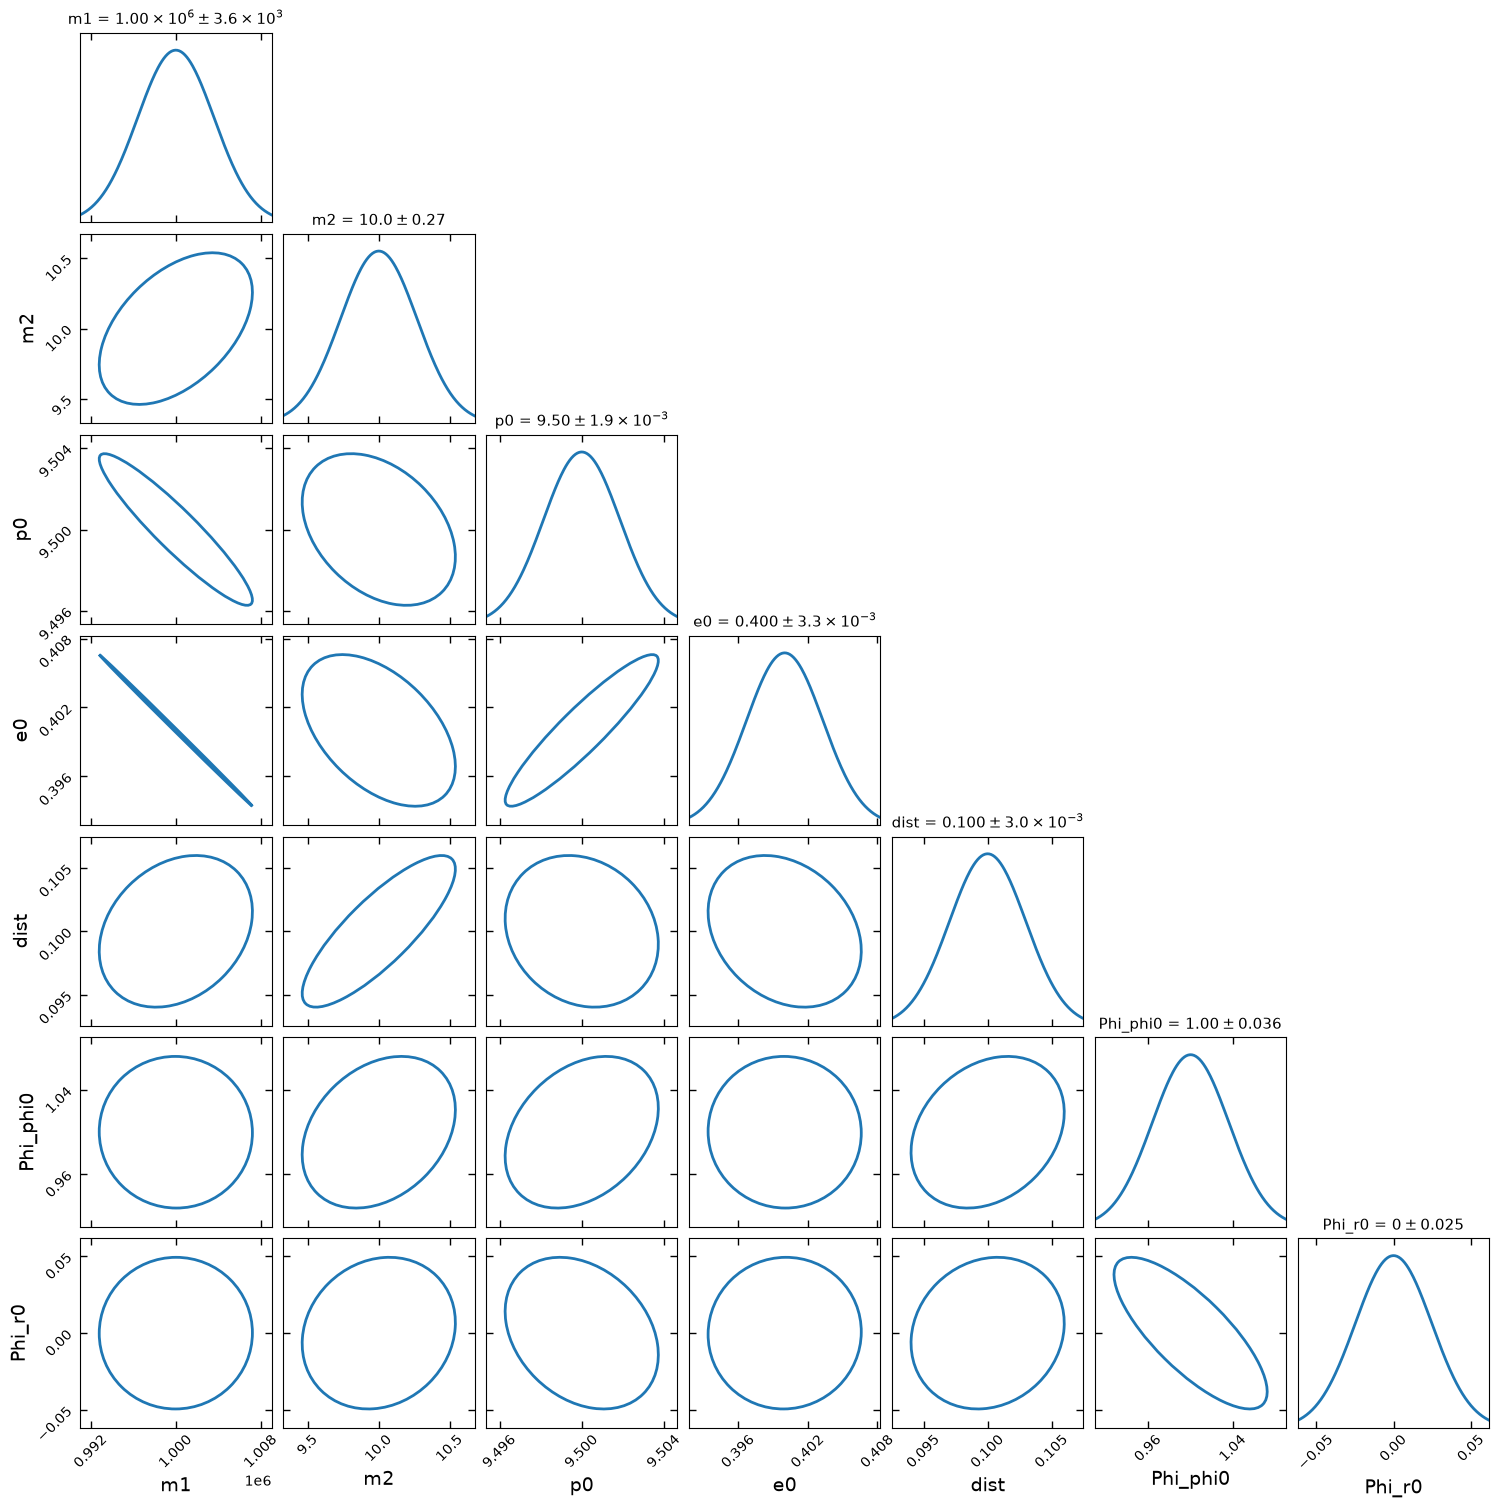

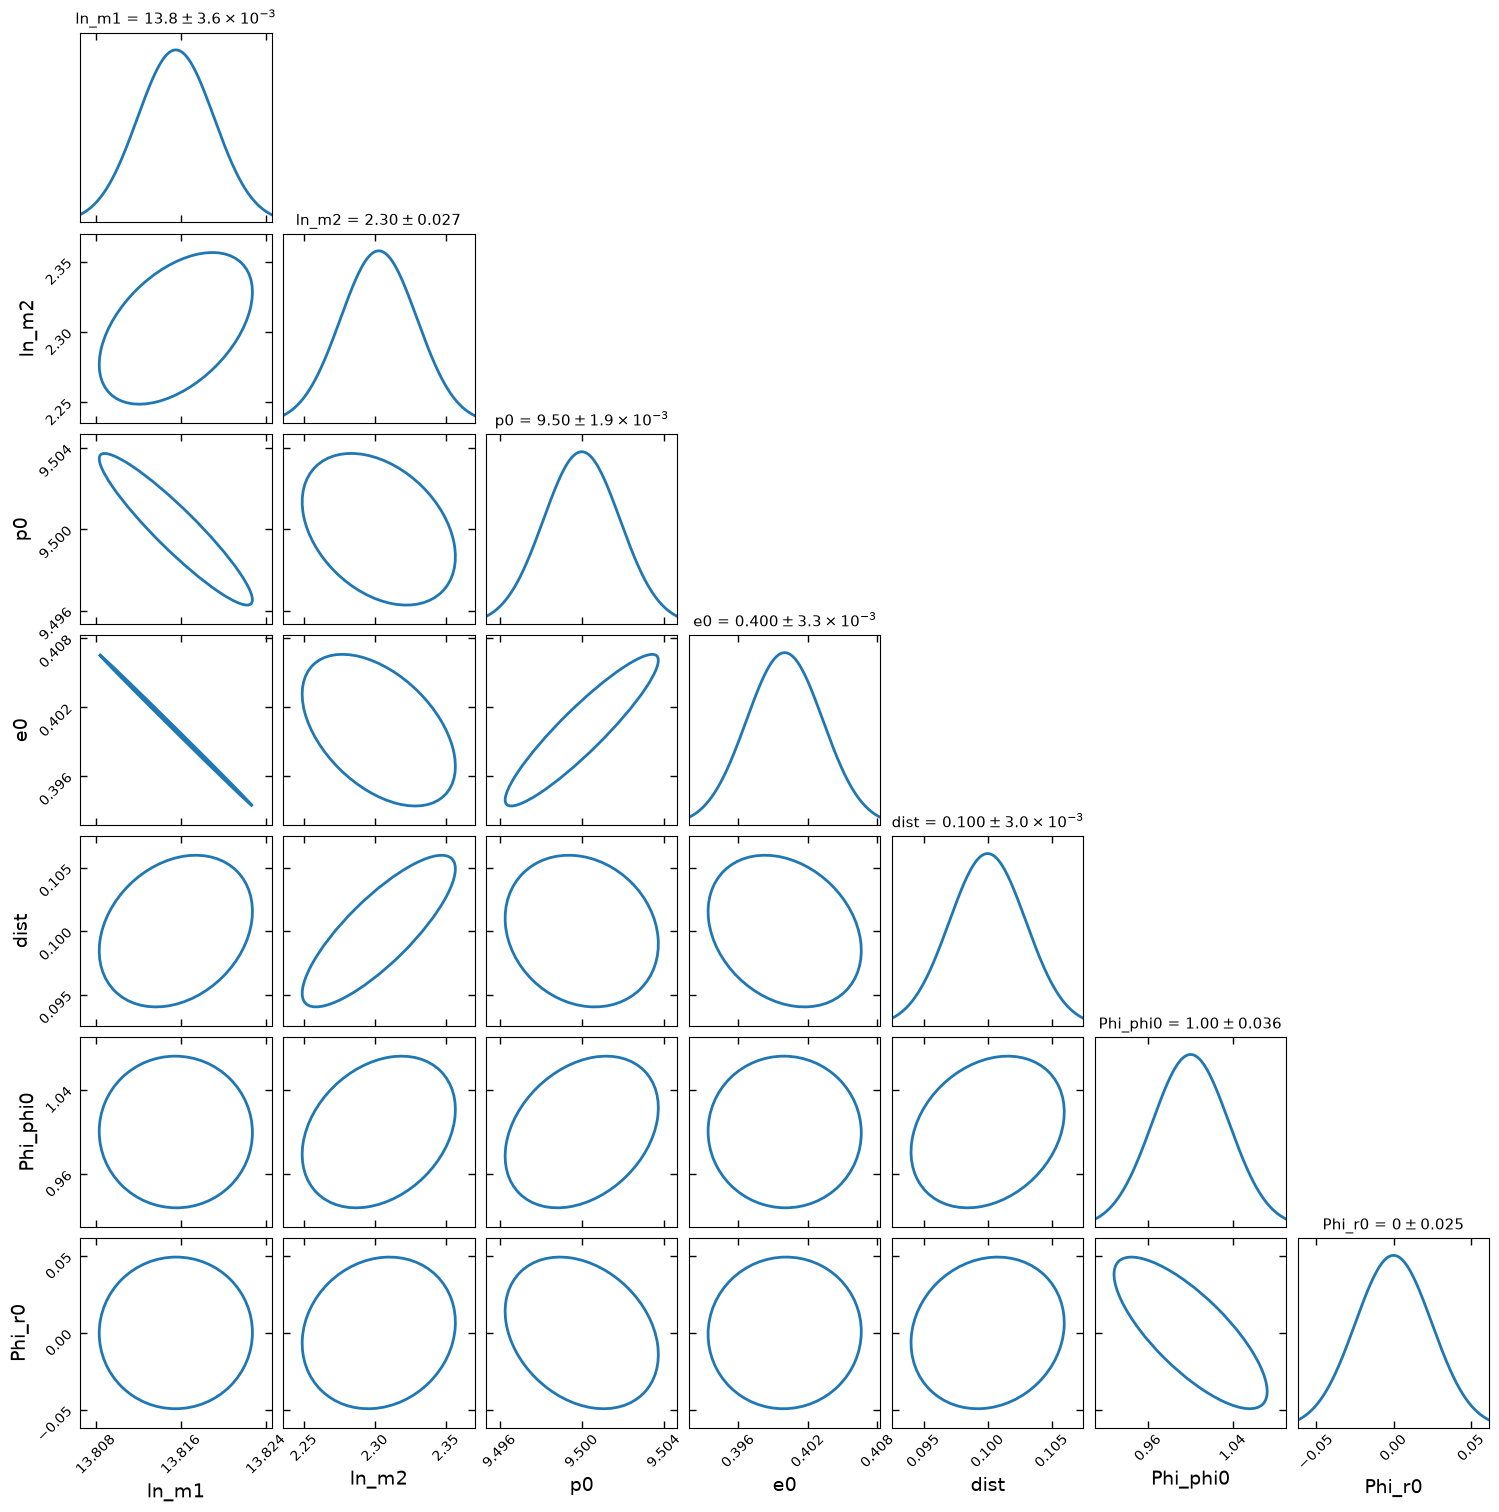

In [6]:
fig, axs = plot_covariance_ellipses(cov, param_names, wave_params)  # m1, m2
plt.show()

fig, axs = plot_covariance_ellipses(cov_log, log_names, log_values)  # ln m1, ln m2
plt.show()

## What this shows

A Fisher matrix can be moved to new parameters with one Jacobian, $\Gamma' = J^{T} \Gamma J$, without new derivatives. Log-masses put all parameters on a similar scale, which lowers the condition number of the Fisher matrix by orders of magnitude and makes its inversion more accurate. The same applies to sampling: an MCMC in $\ln m_1, \ln m_2$ explores parameters of order one, and its posterior can be compared directly with the covariance $\Gamma'^{-1}$.